In [27]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

# -----------------------------
# 1. Dataset & DataLoader
# -----------------------------
transform = transforms.Compose([
    transforms.ToTensor(),
])

train_data = datasets.MNIST(root='./data', train=True, transform=transform, download=True)
train_loader = DataLoader(train_data, batch_size=64, shuffle=True)

# -----------------------------
# 2. Autoencoder (Conv-based)
# -----------------------------
class ConvAutoencoder(nn.Module):
    def __init__(self):
        super(ConvAutoencoder, self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1),  # 28x28 -> 14x14
            nn.ReLU(True),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), # 14x14 -> 7x7
            nn.ReLU(True),
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, 3, stride=2, padding=1, output_padding=1), # 7x7 -> 14x14
            nn.ReLU(True),
            nn.ConvTranspose2d(16, 1, 3, stride=2, padding=1, output_padding=1),  # 14x14 -> 28x28
            nn.Sigmoid(),  # to keep output in [0, 1]
        )

    def forward(self, x):
        latent = self.encoder(x)
        reconstructed = self.decoder(latent)
        return reconstructed, latent

# -----------------------------
# 3. Training
# -----------------------------
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = ConvAutoencoder().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 5
for epoch in range(epochs):
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        reconstructed, _ = model(imgs)
        loss = criterion(reconstructed, imgs)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    print(f"Epoch [{epoch+1}/{epochs}] Loss: {loss.item():.4f}")


Epoch [1/5] Loss: 0.0016
Epoch [2/5] Loss: 0.0009
Epoch [3/5] Loss: 0.0008
Epoch [4/5] Loss: 0.0006
Epoch [5/5] Loss: 0.0005


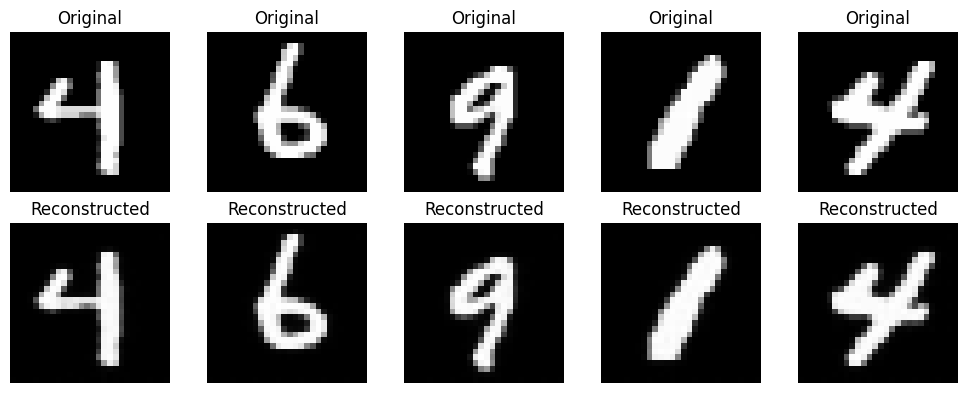

In [28]:
# Get one batch
imgs, _ = next(iter(train_loader))
imgs = imgs.to(device)
reconstructed, latent = model(imgs)

# Plot original and reconstructed
n = 5
plt.figure(figsize=(10, 4))
for i in range(n):
    # Original
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(imgs[i].detach().cpu().squeeze(), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Reconstructed
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(reconstructed[i].detach().cpu().squeeze(), cmap='gray')
    plt.title("Reconstructed")
    plt.axis('off')

plt.tight_layout()
plt.show()


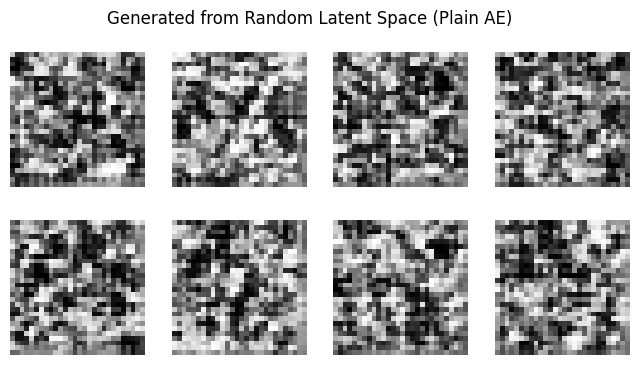

In [29]:
# Generate new images from random latent vectors
with torch.no_grad():
    # Create random latent vectors similar in shape to encoder output
    random_latent = torch.randn(16, 32, 7, 7).to(device)
    generated = model.decoder(random_latent)

# Display generated images
plt.figure(figsize=(8, 4))
for i in range(8):
    ax = plt.subplot(2, 4, i + 1)
    plt.imshow(generated[i].cpu().squeeze(), cmap='gray')
    plt.axis('off')
plt.suptitle("Generated from Random Latent Space (Plain AE)")
plt.show()


Epoch 1, Loss: 173.1998
Epoch 2, Loss: 117.9727
Epoch 3, Loss: 112.1479
Epoch 4, Loss: 109.7277
Epoch 5, Loss: 108.1974


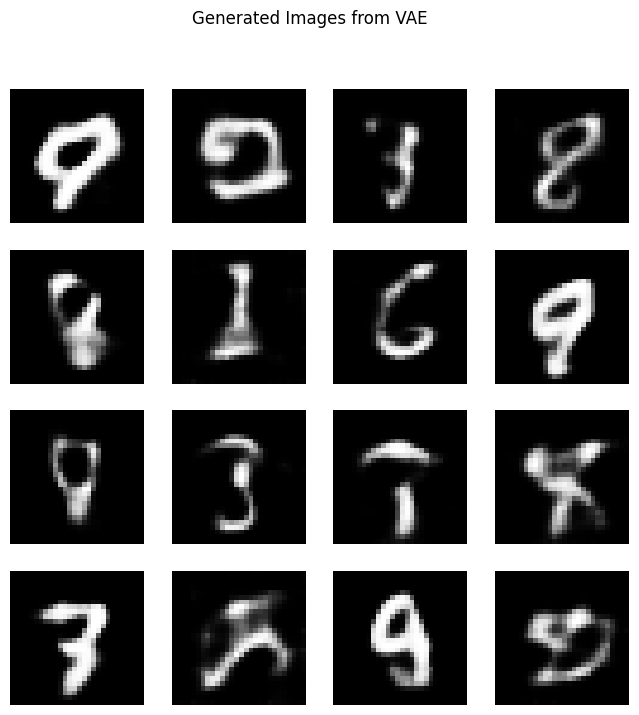

In [30]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ----------------------------
# 1️⃣ Dataset and Loader
# ----------------------------
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

# ----------------------------
# 2️⃣ VAE Model
# ----------------------------
class VAE(nn.Module):
    def __init__(self, latent_dim=32):
        super(VAE, self).__init__()
        self.latent_dim = latent_dim

        # Encoder
        self.enc_conv1 = nn.Conv2d(1, 32, 3, stride=2, padding=1)  # [batch, 32, 14, 14]
        self.enc_conv2 = nn.Conv2d(32, 64, 3, stride=2, padding=1) # [batch, 64, 7, 7]
        self.fc_mu = nn.Linear(64*7*7, latent_dim)
        self.fc_logvar = nn.Linear(64*7*7, latent_dim)

        # Decoder
        self.fc_dec = nn.Linear(latent_dim, 64*7*7)
        self.dec_conv1 = nn.ConvTranspose2d(64, 32, 3, stride=2, padding=1, output_padding=1)
        self.dec_conv2 = nn.ConvTranspose2d(32, 1, 3, stride=2, padding=1, output_padding=1)

    def encode(self, x):
        h = F.relu(self.enc_conv1(x))
        h = F.relu(self.enc_conv2(h))
        h = h.view(h.size(0), -1)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5*logvar)
        eps = torch.randn_like(std)
        return mu + eps*std

    def decode(self, z):
        h = F.relu(self.fc_dec(z))
        h = h.view(-1, 64, 7, 7)
        h = F.relu(self.dec_conv1(h))
        x_recon = torch.sigmoid(self.dec_conv2(h))
        return x_recon

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

# ----------------------------
# 3️⃣ Loss Function
# ----------------------------
def vae_loss(recon_x, x, mu, logvar):
    # Reconstruction loss
    BCE = F.binary_cross_entropy(recon_x, x, reduction='sum')
    # KL divergence
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return BCE + KLD

# ----------------------------
# 4️⃣ Training
# ----------------------------
model = VAE(latent_dim=32).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 5  # you can increase for better results

for epoch in range(epochs):
    model.train()
    train_loss = 0
    for imgs, _ in train_loader:
        imgs = imgs.to(device)
        optimizer.zero_grad()
        recon, mu, logvar = model(imgs)
        loss = vae_loss(recon, imgs, mu, logvar)
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
    print(f"Epoch {epoch+1}, Loss: {train_loss/len(train_loader.dataset):.4f}")

# ----------------------------
# 5️⃣ Generate Random Images
# ----------------------------
model.eval()
with torch.no_grad():
    # Sample 16 random latent vectors
    z = torch.randn(16, 32).to(device)
    generated = model.decode(z).cpu()

# Display generated images
plt.figure(figsize=(8,8))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.imshow(generated[i].squeeze(), cmap='gray')
    plt.axis('off')
plt.suptitle("Generated Images from VAE")
plt.show()
